In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

from matplotlib import pyplot as plt

import numpy as np
import pandas as pd
import seaborn as sns
import random
import time
from pathlib import Path
from PIL import Image
from IPython.display import display
import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets ,transforms, models

In [6]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("azaemon/preprocessed-ct-scans-for-covid19")

print("Path to dataset files:", path)

Resuming download from 1023410176 bytes (2826715273 bytes left)...
Resuming download to /root/.cache/kagglehub/datasets/azaemon/preprocessed-ct-scans-for-covid19/2.archive (1023410176/3850125449) bytes left.


100%|██████████| 3.59G/3.59G [00:29<00:00, 96.6MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/azaemon/preprocessed-ct-scans-for-covid19/versions/2


In [7]:
DATA_ROOT =Path("/root/.cache/kagglehub/datasets/azaemon/preprocessed-ct-scans-for-covid19/versions/2")
OUTPUT_DIR     = Path("outputs")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE  = 16
IMG_SHAPE   = 224
EPOCHS      = 25
MODEL_NAME  = "mobilenet_v3_large"
FINE_TUNING = True

SMOKE_TEST = False
if SMOKE_TEST:
    EPOCHS = 1

# Apple GPU if available, otherwise CPU
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

# Mixed precision runs on MPS, but in my tests it was slower than plain float32 for this model
USE_AMP = False

# 4 workers load images fast enough to keep the GPU busy. pin_memory only helps on NVIDIA GPUs.
NUM_WORKERS = 4
PIN_MEMORY  = False

print(f"PyTorch {torch.__version__} | device: {device} | epochs: {EPOCHS}")

PyTorch 2.11.0+cu130 | device: cpu | epochs: 25


In [21]:
import torch

# Configure PyTorch to use CUDA GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))

print(f"Selected device: {device}")
if device.type == 'cuda':
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")

Selected device: cuda
GPU Name: Tesla T4


In [11]:
# Always derive DATA_ROOT from the original download path to prevent nested path accumulation
DATA_ROOT = Path(path) / "Preprocessed CT scans"

EXPECTED_CLASSES = {"nCT", "NiCT", "pCT"}

classes = sorted(d.name for d in DATA_ROOT.iterdir() if d.is_dir())
assert EXPECTED_CLASSES <= set(classes), f"Expected the folders {sorted(EXPECTED_CLASSES)} in {DATA_ROOT}, found {classes}"

print("Classes:", classes)

Classes: ['NiCT', 'nCT', 'pCT']


In [12]:
EXPECTED_COUNTS = {"nCT": 9979, "NiCT": 5705, "pCT": 4001}
IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def count_images(folder):
    return sum(1 for p in Path(folder).iterdir() if p.suffix.lower() in IMAGE_EXTS)

for c in classes:
    n = count_images(DATA_ROOT / c)
    print(f"{c:5s} {n:6,} images")
    assert n == EXPECTED_COUNTS[c], f"{c}: found {n} images, expected {EXPECTED_COUNTS[c]}"

NiCT   5,705 images
nCT    9,979 images
pCT    4,001 images


In [25]:
# Transforms
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize(256),
        transforms.RandomResizedCrop(IMG_SHAPE),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225]),
    ]),
    'valid': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(IMG_SHAPE),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225]),
    ]),
}

base = datasets.ImageFolder(DATA_ROOT)
classes = base.classes
print("Classes:", classes)

target = {
    "pCT":  {"train": 2800, "valid": 600,  "test": 601},
    "NiCT": {"train": 3993, "valid": 855,  "test": 857},
    "nCT":  {"train": 6985, "valid": 1496, "test": 1498},
}

rng = random.Random(42)
idx_by_class = {c: [] for c in classes}
for i, (_, y) in enumerate(base.samples):
    idx_by_class[classes[y]].append(i)

train_idx, val_idx, test_idx = [], [], []
for c in classes:
    idxs = idx_by_class[c]
    rng.shuffle(idxs)
    t = target[c]["train"]; v = target[c]["valid"]; s = target[c]["test"]
    need = t + v + s
    if len(idxs) < need:
        raise ValueError(f"{c}: found {len(idxs)} images, need {need}.")
    train_idx += idxs[:t]
    val_idx   += idxs[t:t+v]
    test_idx  += idxs[t+v:t+v+s]

train_ds = Subset(datasets.ImageFolder(DATA_ROOT, transform=data_transforms['train']), train_idx)
val_ds   = Subset(datasets.ImageFolder(DATA_ROOT, transform=data_transforms['valid']), val_idx)
test_ds  = Subset(datasets.ImageFolder(DATA_ROOT, transform=data_transforms['valid']), test_idx)

# Using 0 workers to bypass Colab multiprocessing/shared-memory limitations entirely
SAFE_NUM_WORKERS = 0
loader_kwargs = dict(batch_size=BATCH_SIZE, num_workers=SAFE_NUM_WORKERS, pin_memory=PIN_MEMORY,
                     persistent_workers=False)
dataloaders = {
    'trainloader': DataLoader(train_ds, shuffle=True,  **loader_kwargs),
    'validloader': DataLoader(val_ds,   shuffle=False, **loader_kwargs),
    'testloader' : DataLoader(test_ds,  shuffle=False, **loader_kwargs),
}

print(f"Split: {len(train_idx):,} train / {len(val_idx):,} validation / {len(test_idx):,} test")

xb, yb = next(iter(dataloaders['trainloader']))
print("Batch:", xb.shape, yb.shape)

Classes: ['NiCT', 'nCT', 'pCT']
Split: 13,778 train / 2,951 validation / 2,956 test
Batch: torch.Size([16, 3, 224, 224]) torch.Size([16])


In [14]:
class_to_name = {
    "nCT":  "Normal CT scan",
    "NiCT": "Non-informative CT (lungs not visible enough to judge)",
    "pCT":  "COVID-19 positive CT scan",
}

class_to_idx = base.class_to_idx
idx_to_class = {v: k for k, v in class_to_idx.items()}
idx_to_name  = {i: class_to_name[idx_to_class[i]] for i in idx_to_class}

print("class_to_idx:", class_to_idx)
print("idx_to_name:", idx_to_name)

class_to_idx: {'NiCT': 0, 'nCT': 1, 'pCT': 2}
idx_to_name: {0: 'Non-informative CT (lungs not visible enough to judge)', 1: 'Normal CT scan', 2: 'COVID-19 positive CT scan'}


In [15]:
class Classifier(nn.Module):
    def __init__(
        self,
        input_size: int,
        output_size: int,
        hidden_layers=(1280,),
        drop_p: float = 0.2,
        use_log_softmax: bool = True
    ):
        super().__init__()

        if isinstance(hidden_layers, int):
            hidden_layers = [hidden_layers]

        layers = []
        prev = input_size

        for h in (hidden_layers or []):
            layers.append(nn.Linear(prev, h))
            layers.append(nn.ReLU(inplace=True))
            layers.append(nn.Dropout(p=drop_p))
            prev = h

        layers.append(nn.Linear(prev, output_size))

        self.net = nn.Sequential(*layers)
        self.use_log_softmax = use_log_softmax

    def forward(self, x):
        x = self.net(x)
        return F.log_softmax(x, dim=1) if self.use_log_softmax else x

In [16]:
def validation(model, validloader, criterion, device):
    """Return the average loss and the accuracy of the model on one data split."""
    model.eval()
    loss_sum = 0.0
    correct  = 0
    n        = 0

    with torch.no_grad():
        for inputs, labels in validloader:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(inputs)
            loss    = criterion(outputs, labels)

            bs = labels.size(0)
            loss_sum += loss.item() * bs

            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            n += bs

    avg_loss = loss_sum / n if n else 0.0
    avg_acc  = correct  / n if n else 0.0
    return avg_loss, avg_acc

In [17]:
def format_duration(seconds):
    m, s = divmod(int(round(seconds)), 60)
    h, m = divmod(m, 60)
    return f"{h}h{m:02d}m{s:02d}s" if h else f"{m}m{s:02d}s"

def training(model, criterion, optimizer, device,
             trainloader, validloader,
             epochs: int = 5, print_every: int = 50, use_amp: bool = False):
    """Train the model and return the validation loss/accuracy and duration of every epoch."""
    model.to(device)
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)

    print(f"Training on {device} (mixed precision: {use_amp})")

    history = {"val_loss": [], "val_acc": [], "epoch_time": []}
    t_start = time.perf_counter()

    for e in range(1, epochs + 1):
        t_epoch = time.perf_counter()
        model.train()
        running_loss = 0.0

        for step, (inputs, labels) in enumerate(trainloader, 1):
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item()

            if step % print_every == 0:
                val_loss, val_acc = validation(model, validloader, criterion, device)
                avg_train = running_loss / print_every
                print(f"Epoch {e}/{epochs}  Step {step}/{len(trainloader)}  "
                      f"TrainLoss {avg_train:.4f}  ValLoss {val_loss:.4f}  ValAcc {val_acc:.4f}  "
                      f"[{format_duration(time.perf_counter() - t_epoch)}]")
                running_loss = 0.0
                model.train()

        val_loss, val_acc = validation(model, validloader, criterion, device)
        epoch_time = time.perf_counter() - t_epoch
        eta = (time.perf_counter() - t_start) / e * (epochs - e)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["epoch_time"].append(epoch_time)
        print(f"Epoch {e}/{epochs} done  ValLoss {val_loss:.4f}  ValAcc {val_acc:.4f}  "
              f"| took {format_duration(epoch_time)}, about {format_duration(eta)} left")

    print(f"Training finished in {format_duration(time.perf_counter() - t_start)}")
    return history

In [18]:
hyper_parameters = {
    'input_size'   : 960,
    'output_size'  : len(classes),
    'hidden_layers': [1280],
    'drop_p'       : 0.2,
    'learn_rate'   : 1e-4,
    'epochs'       : EPOCHS,
    'model'        : MODEL_NAME,
}

classifier = Classifier(
    input_size    = hyper_parameters['input_size'],
    output_size   = hyper_parameters['output_size'],
    hidden_layers = hyper_parameters['hidden_layers'],
    drop_p        = hyper_parameters['drop_p'],
    use_log_softmax = True
)

model = models.mobilenet_v3_large(weights="DEFAULT")

if not FINE_TUNING:
    for p in model.features.parameters():
        p.requires_grad = False

model.classifier = classifier

model = model.to(device)

print(model.classifier)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 63.2MB/s]


Classifier(
  (net): Sequential(
    (0): Linear(in_features=960, out_features=1280, bias=True)
    (1): ReLU(inplace=True)
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=1280, out_features=3, bias=True)
  )
)


In [19]:
model = model.to(device)

criterion = nn.NLLLoss()

optimizer = optim.AdamW(
    (p for p in model.parameters() if p.requires_grad),
    lr=hyper_parameters['learn_rate'],
    weight_decay=1e-4
)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {total_params:,} | lr={hyper_parameters['learn_rate']} | device={device}")

Trainable parameters: 4,205,875 | lr=0.0001 | device=cpu


In [22]:
# Move model to GPU and recreate optimizer for correct device parameters
model = model.to(device)

optimizer = optim.AdamW(
    (p for p in model.parameters() if p.requires_grad),
    lr=hyper_parameters['learn_rate'],
    weight_decay=1e-4
)

print(f"Model successfully moved to: {device}")

Model successfully moved to: cuda


In [26]:
# Run training on the GPU with the updated safe dataloaders
history = training(
    model,
    criterion,
    optimizer,
    device,
    trainloader = dataloaders['trainloader'],
    validloader = dataloaders['validloader'],
    epochs = hyper_parameters['epochs'],
    use_amp = USE_AMP,
)

Training on cuda (mixed precision: False)
Epoch 1/25  Step 50/862  TrainLoss 0.3905  ValLoss 0.5334  ValAcc 0.7919  32s]
Epoch 1/25  Step 100/862  TrainLoss 0.3627  ValLoss 0.4574  ValAcc 0.8285  00s]
Epoch 1/25  Step 150/862  TrainLoss 0.3266  ValLoss 0.3323  ValAcc 0.8939  29s]
Epoch 1/25  Step 200/862  TrainLoss 0.2848  ValLoss 0.3749  ValAcc 0.8739  56s]
Epoch 1/25  Step 250/862  TrainLoss 0.2973  ValLoss 0.2873  ValAcc 0.8980  25s]
Epoch 1/25  Step 300/862  TrainLoss 0.2721  ValLoss 0.3837  ValAcc 0.8760  53s]
Epoch 1/25  Step 350/862  TrainLoss 0.2279  ValLoss 0.3232  ValAcc 0.8987  21s]
Epoch 1/25  Step 400/862  TrainLoss 0.2085  ValLoss 0.4490  ValAcc 0.8360  49s]
Epoch 1/25  Step 450/862  TrainLoss 0.2648  ValLoss 0.2155  ValAcc 0.9427  17s]
Epoch 1/25  Step 500/862  TrainLoss 0.2373  ValLoss 0.2092  ValAcc 0.9454  46s]
Epoch 1/25  Step 550/862  TrainLoss 0.2483  ValLoss 0.2226  ValAcc 0.9278  14s]
Epoch 1/25  Step 600/862  TrainLoss 0.2390  ValLoss 0.2442  ValAcc 0.9132  42s]

In [27]:
# Evaluate the model on the test dataset
test_loss, test_acc = validation(model, dataloaders['testloader'], criterion, device)

print(f"Final Test Results:")
print(f"-------------------")
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

Final Test Results:
-------------------
Test Loss:     0.0509
Test Accuracy: 97.73%


In [28]:
train_loss, train_acc = validation(model, dataloaders['trainloader'], criterion, device)
val_loss,   val_acc   = validation(model, dataloaders['validloader'], criterion, device)

print(f"Train: acc = {train_acc:.4f} ({train_acc*100:.2f}%), loss = {train_loss:.4f}")
print(f"Valid: acc = {val_acc:.4f} ({val_acc*100:.2f}%), loss = {val_loss:.4f}")

Train: acc = 0.9685 (96.85%), loss = 0.0882
Valid: acc = 0.9800 (98.00%), loss = 0.0640


In [29]:
checkpoint = {
    "arch": MODEL_NAME,
    "input_size": hyper_parameters["input_size"],
    "output_size": hyper_parameters["output_size"],
    "hidden_layers": hyper_parameters["hidden_layers"],
    "drop_p": hyper_parameters["drop_p"],
    "fine_tuning": FINE_TUNING,
    "img_shape": IMG_SHAPE,
    "class_to_idx": base.class_to_idx,
    "classes": classes,
    "state_dict": model.state_dict(),
}

filepath = CHECKPOINT_DIR / (f"{MODEL_NAME}_smoke.pth" if SMOKE_TEST else f"{MODEL_NAME}.pth")
torch.save(checkpoint, filepath)
print("Saved", filepath)

Saved outputs/checkpoints/mobilenet_v3_large.pth


In [30]:
def load_checkpoint(filepath, device):
    """Rebuild the trained model from a checkpoint file, ready for predictions."""
    ckpt = torch.load(filepath, map_location=device)
    assert ckpt["arch"] == "mobilenet_v3_large", f"Unexpected architecture: {ckpt['arch']}"

    model = models.mobilenet_v3_large(weights=None)
    model.classifier = Classifier(
        input_size=ckpt["input_size"],
        output_size=ckpt["output_size"],
        hidden_layers=ckpt["hidden_layers"],
        drop_p=ckpt["drop_p"],
    )
    model.load_state_dict(ckpt["state_dict"])
    model.class_to_idx = ckpt["class_to_idx"]
    model.classes = ckpt["classes"]
    return model.to(device).eval()

In [31]:
t0 = time.perf_counter()
model = load_checkpoint(filepath, device)
print(f"Loaded {filepath} in {time.perf_counter() - t0:.2f}s")

Loaded outputs/checkpoints/mobilenet_v3_large.pth in 0.19s


In [32]:
def process_image(image_path):
    """Load an image and prepare it for the model. Returns a tensor of shape [1, 3, 224, 224]."""
    im = Image.open(image_path).convert("RGB")

    preprocess = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(IMG_SHAPE),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225]),
    ])
    return preprocess(im).unsqueeze(0)

In [33]:
def imshow(image, ax=None, title=None, denorm=True):
    """Display a tensor image. Accepts [3,H,W] or [1,3,H,W]."""
    if ax is None:
        fig, ax = plt.subplots()

    if torch.is_tensor(image):
        img = image.detach().cpu()
        if img.dim() == 4:
            img = img[0]
        img = img.permute(1, 2, 0).numpy()
    else:
        img = np.asarray(image)

    if denorm:
        mean = np.array([0.485, 0.456, 0.406])
        std  = np.array([0.229, 0.224, 0.225])
        img = std * img + mean

    img = np.clip(img, 0, 1)
    ax.imshow(img)
    if title is not None:
        ax.set_title(title)
    ax.axis('off')
    return ax

Test image: pCT/pCT1624.jpg (class pCT)


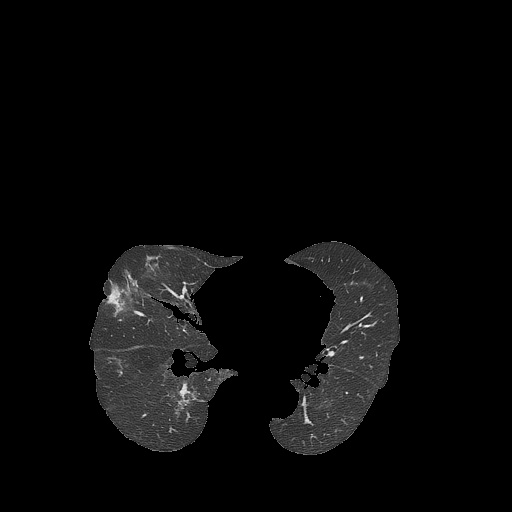

In [34]:
idx = random.choice(test_idx)
img_path, y = base.samples[idx]
print(f"Test image: {Path(img_path).relative_to(DATA_ROOT)} (class {classes[y]})")

display(Image.open(img_path).convert("RGB"))

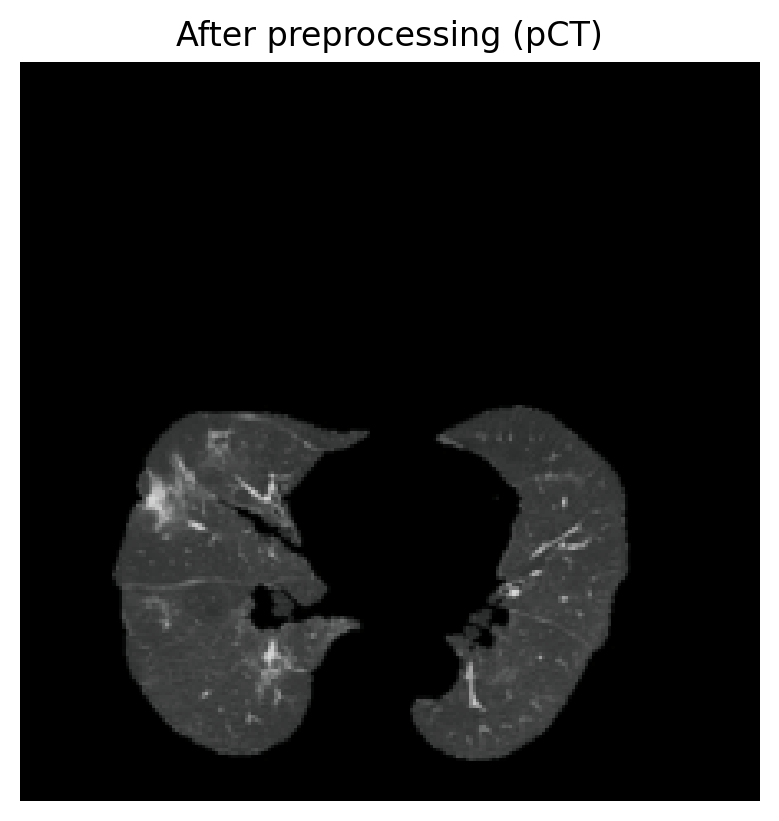

In [35]:
image = process_image(img_path)
imshow(image, title=f"After preprocessing ({classes[y]})");

In [36]:
def predict(image_path, model, topk=3):
    """Return the top-k probabilities and their class folder names for one image."""
    model.eval()
    x = process_image(image_path).to(device)

    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)

    topk = min(topk, probs.shape[1])
    prob_vals, idxs = probs.topk(topk, dim=1)

    idx_to_class = {v: k for k, v in model.class_to_idx.items()}
    classes_pred = [idx_to_class[i.item()] for i in idxs[0]]
    return prob_vals[0].cpu().numpy(), classes_pred

In [37]:
def predict_classes_names(image_path, model, cat_to_name=None, topk=3):
    """Like predict(), but returns readable class names when a mapping is given."""
    probs, classes_pred = predict(image_path, model, topk=topk)
    if cat_to_name:
        return probs, [cat_to_name.get(c, c) for c in classes_pred]
    return probs, classes_pred

In [38]:
def prediction_displaying(image_path, probs, classes_names, cat_to_name=None):
    """Plot the image (titled with its true class) above a bar chart of the predicted probabilities."""
    image = Image.open(image_path).convert("RGB")

    fig, (ax1, ax2) = plt.subplots(
        nrows=2, ncols=1, figsize=(7, 9),
        gridspec_kw={"height_ratios": [3, 2]}
    )

    folder_label = Path(image_path).parent.name
    title = cat_to_name.get(folder_label, folder_label) if cat_to_name else folder_label

    ax1.imshow(image)
    ax1.set_title(title)
    ax1.axis("off")

    probs = np.asarray(probs).reshape(-1)
    y_pos = np.arange(len(probs))

    ax2.barh(y_pos, probs, align="center")
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels(classes_names)
    ax2.set_xlim(0, 1)
    ax2.set_xlabel("Probability")
    ax2.set_title("Class Probability")
    ax2.invert_yaxis()

    for i, p in enumerate(probs):
        ax2.text(min(p + 0.02, 0.98), i, f"{p*100:.1f}%", va="center")

    plt.tight_layout()
    return fig, (ax1, ax2)

Test image: nCT/nCT7835.jpg


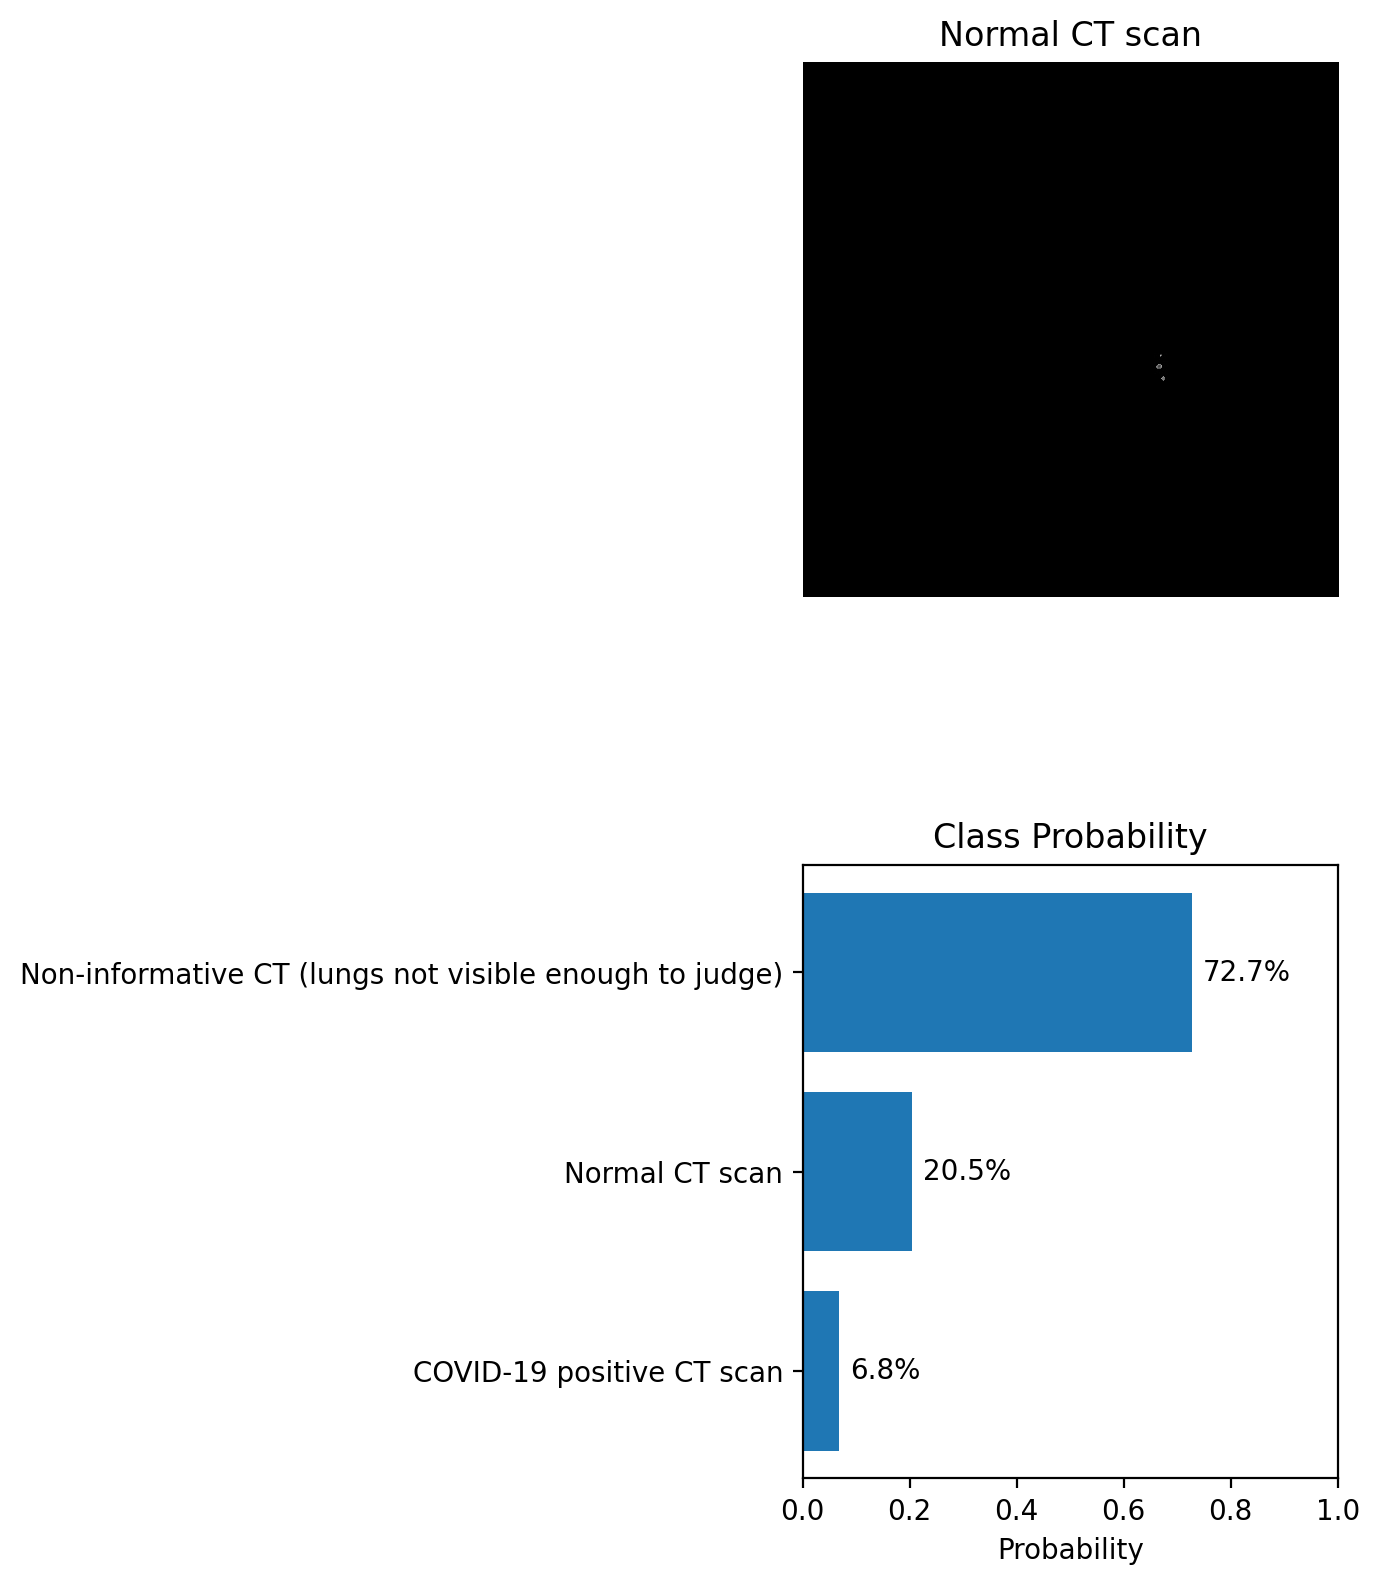

Ground truth: Normal CT scan
 72.68%  Non-informative CT (lungs not visible enough to judge)
 20.52%  Normal CT scan
  6.80%  COVID-19 positive CT scan


In [39]:
idx = random.choice(test_idx)
image_path, y_true = base.samples[idx]
print("Test image:", Path(image_path).relative_to(DATA_ROOT))

probs, names = predict_classes_names(image_path, model, cat_to_name=class_to_name, topk=len(classes))
prediction_displaying(image_path, probs, names, cat_to_name=class_to_name)
plt.show()

print("Ground truth:", class_to_name[classes[y_true]])
for p, n in zip(probs, names):
    print(f"{p:7.2%}  {n}")


=== Classification Report ===

                                                        precision    recall  f1-score   support

Non-informative CT (lungs not visible enough to judge)       0.97      0.96      0.97       857
                                        Normal CT scan       0.98      0.98      0.98      1498
                             COVID-19 positive CT scan       0.98      0.98      0.98       601

                                              accuracy                           0.98      2956
                                             macro avg       0.98      0.98      0.98      2956
                                          weighted avg       0.98      0.98      0.98      2956



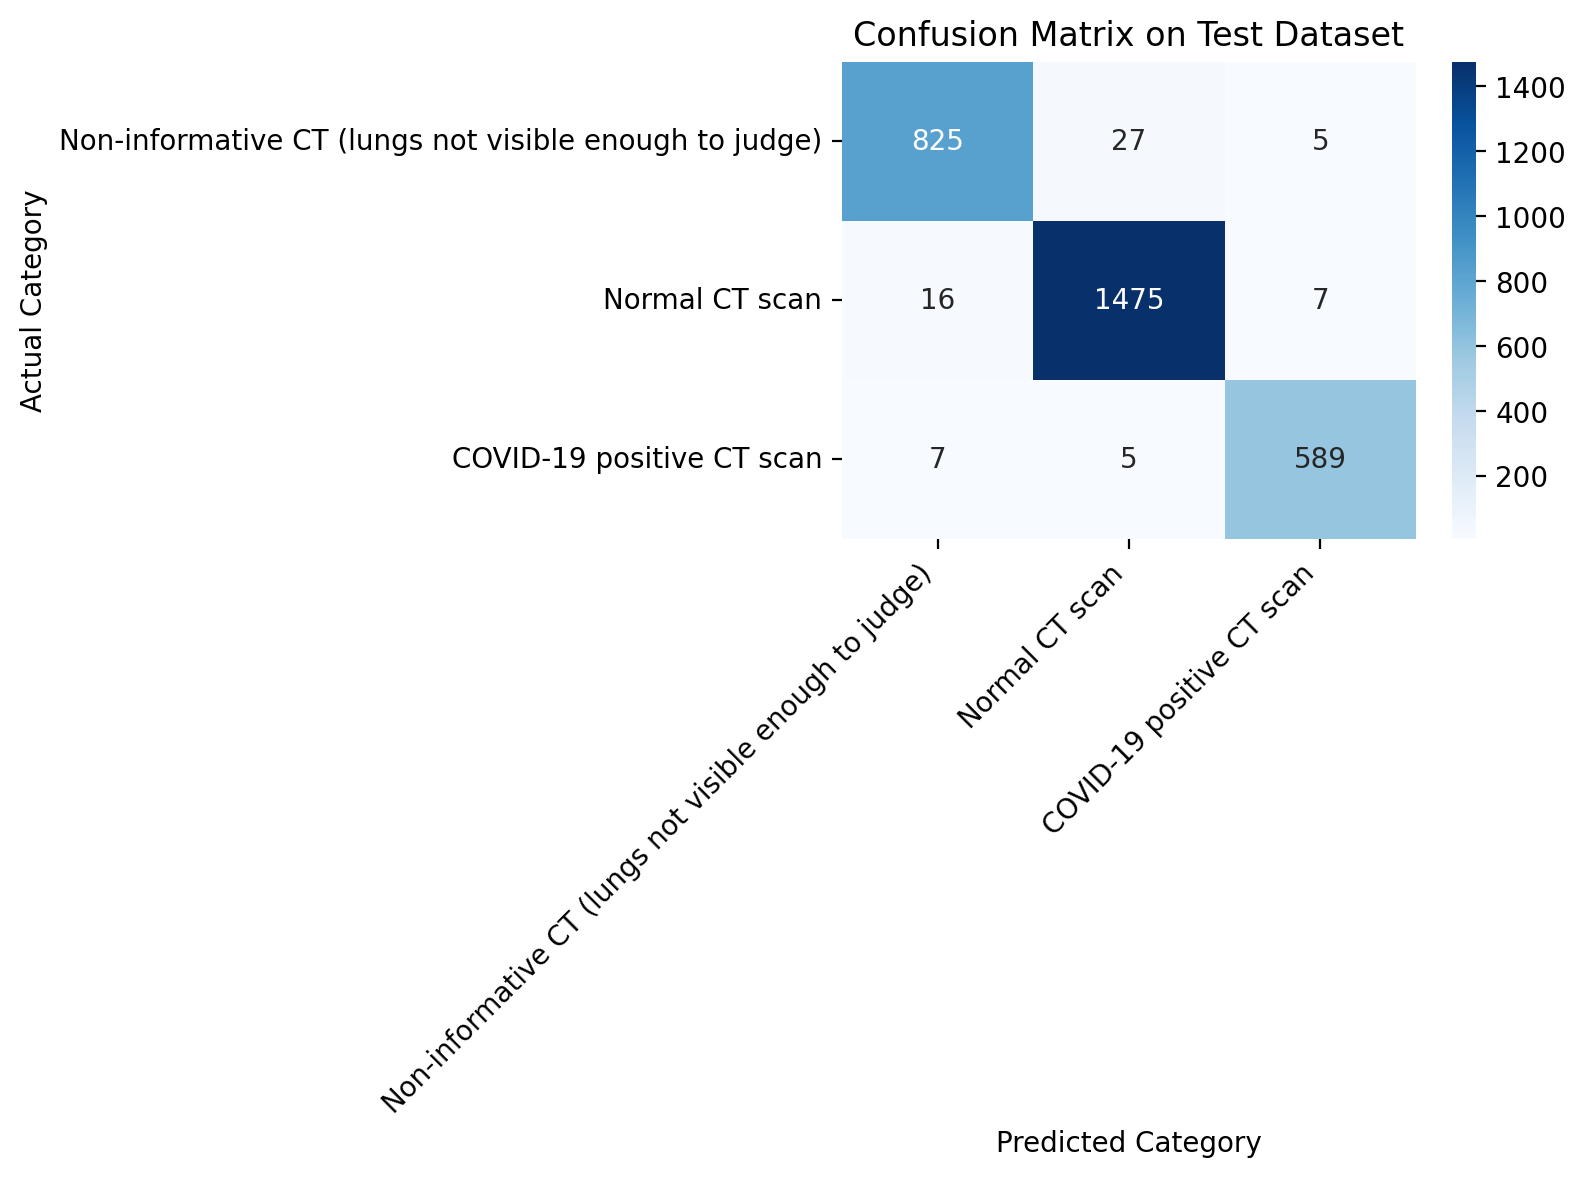

In [40]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

def evaluate_class_performance(model, testloader, device, classes, class_to_name):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in testloader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            preds = outputs.argmax(dim=1).cpu().numpy()

            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)

    # Generate and print classification report
    readable_labels = [class_to_name[c] for c in classes]
    print("\n=== Classification Report ===\n")
    print(classification_report(all_labels, all_preds, target_names=readable_labels))

    # Plot Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=readable_labels, yticklabels=readable_labels)
    plt.title('Confusion Matrix on Test Dataset')
    plt.ylabel('Actual Category')
    plt.xlabel('Predicted Category')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

# Run the evaluation
evaluate_class_performance(model, dataloaders['testloader'], device, classes, class_to_name)